In [123]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (mean_absolute_error, accuracy_score, r2_score, f1_score, roc_auc_score, precision_score)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor, XGBClassifier

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam

In [124]:
cutoff_date = pd.Timestamp('2021-10-19', tz= 'UTC')

In [125]:
df_1h= pd.read_parquet("1h_btc_sentiment.parquet")

In [126]:
df_15min= pd.read_parquet("15min_btc_sentiment.parquet")

In [127]:
df_cluster_1h= pd.read_parquet("1h_btc_sentiment_cluster.parquet")

In [128]:
df_cluster_15min= pd.read_parquet("15min_btc_sentiment_cluster.parquet")

In [132]:
df_meta_cluster_1h= pd.read_parquet("1h_btc_sentiment_meta_cluster.parquet")

In [130]:
df_meta_cluster_15min= pd.read_parquet("15min_btc_sentiment_meta_cluster.parquet")

In [134]:
keep_base = ["return", "return_class"]

#keep_cluster = [c for c in df_cluster_1h.columns if c.startswith("sentiment_mean_c") or c.startswith("sentiment_weighted_c")]

keep_cluster = [c for c in df_meta_cluster_1h.columns if c.startswith("sentiment_mean_c") or c.startswith("sentiment_weighted_c")]

keep_sentiment= ["sentiment_mean", "sentiment_weighted"]

In [135]:
#df= df_1h[keep_base + keep_sentiment].copy()
#df= df_15min[keep_base + keep_sentiment].copy()
#df= df_cluster_1h[keep_base + keep_cluster].copy()
#df= df_cluster_15min[keep_base + keep_cluster].copy()
df= df_meta_cluster_1h[keep_base + keep_cluster].copy()
#df= df_meta_cluster_15min[keep_base + keep_cluster].copy()

In [136]:
df.columns

Index(['return', 'return_class', 'sentiment_mean_c1.0', 'sentiment_mean_c2.0',
       'sentiment_mean_c3.0', 'sentiment_mean_c4.0', 'sentiment_mean_c5.0',
       'sentiment_mean_c6.0', 'sentiment_mean_c7.0', 'sentiment_mean_c8.0',
       'sentiment_weighted_c1.0', 'sentiment_weighted_c2.0',
       'sentiment_weighted_c3.0', 'sentiment_weighted_c4.0',
       'sentiment_weighted_c5.0', 'sentiment_weighted_c6.0',
       'sentiment_weighted_c7.0', 'sentiment_weighted_c8.0'],
      dtype='object')

In [137]:
df['volatility_4h'] = df['return'].rolling('4h').std()
df['volatility_12h'] = df['return'].rolling('12h').std()
df['volatility_24h'] = df['return'].rolling('24h').std()
df['mean_return_4h'] = df['return'].rolling('4h').mean()
df['mean_return_12h'] = df['return'].rolling('12h').mean()
df['mean_return_24h'] = df['return'].rolling('24h').mean()
df['hour_sin'] = np.sin(2*np.pi*df.index.hour / 24)
df['hour_cos'] = np.cos(2*np.pi*df.index.hour / 24)
df['dow_sin'] = np.sin(2*np.pi*df.index.dayofweek / 7)
df['dow_cos'] = np.cos(2*np.pi*df.index.dayofweek / 7)
df['target_return'] = df['return'].shift(-1)
df['target_return_class'] = df['return_class'].shift(-1)

In [138]:
base_features = [
    'return',
    'volatility_4h',
    'volatility_12h',
    'volatility_24h',
    'mean_return_4h',
    'mean_return_12h',
    'mean_return_24h',
    'hour_sin',
    'hour_cos',
    'dow_sin',
    'dow_cos',
]


sent_mean_cols = [c for c in df.columns if c.startswith("sentiment_mean_c")]
sent_weight_cols = [c for c in df.columns if c.startswith("sentiment_weighted_c")]

features_raw_weighted = base_features + ["sentiment_weighted"]
features_raw_mean = base_features + ["sentiment_mean"]
features_cluster_weighted = base_features + sent_weight_cols#sent_mean_cols
features_cluster_mean = base_features + sent_mean_cols
features= features_cluster_weighted

In [139]:
df["return_class"].value_counts()

return_class
2    3301
0    3150
1    2309
Name: count, dtype: int64

In [140]:
needed= features+ ["target_return", "target_return_class"]
df = df.dropna(subset=needed).copy()

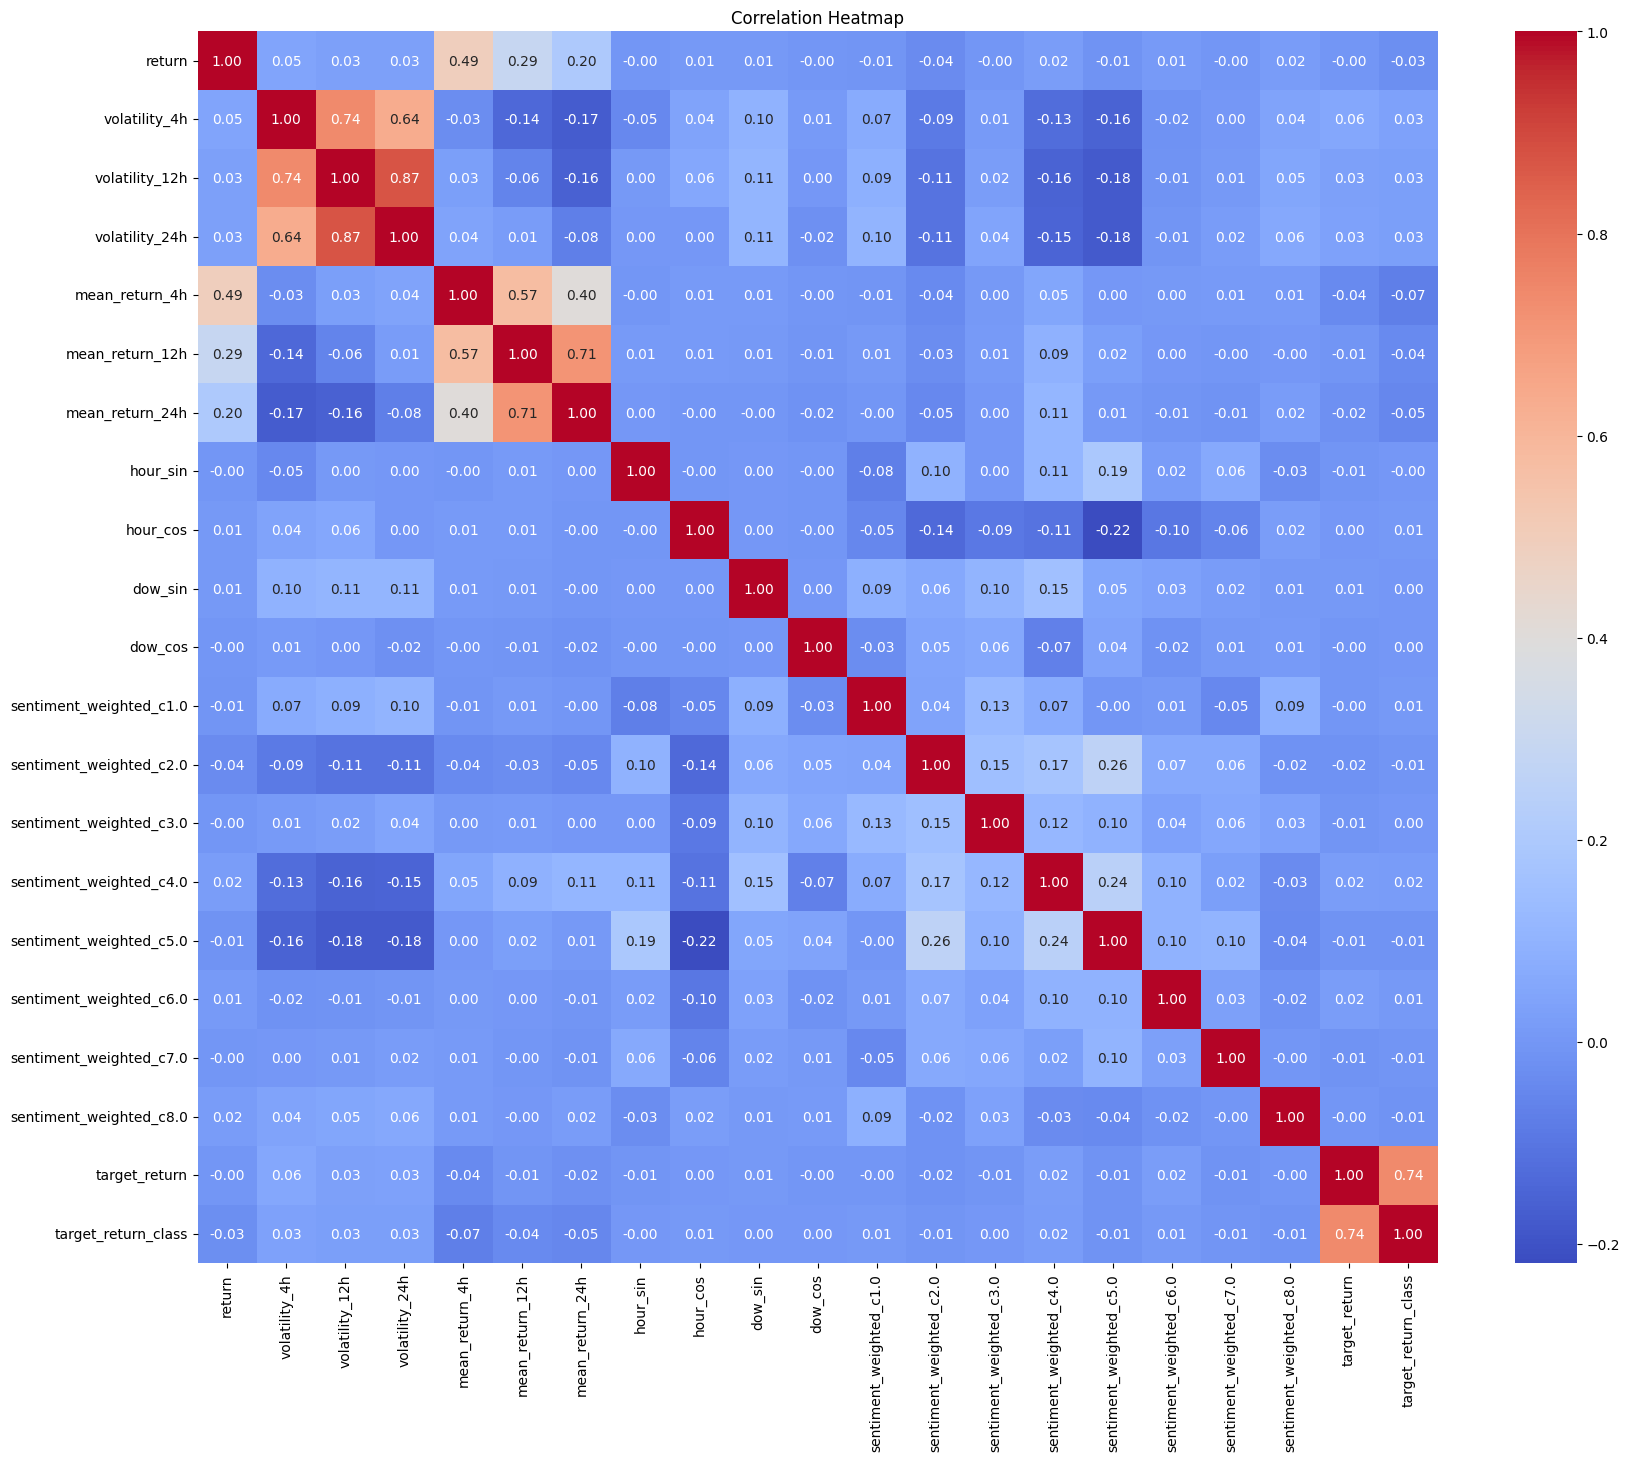

In [141]:
plt.figure(figsize=(20, 16))
sns.heatmap(df[needed].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

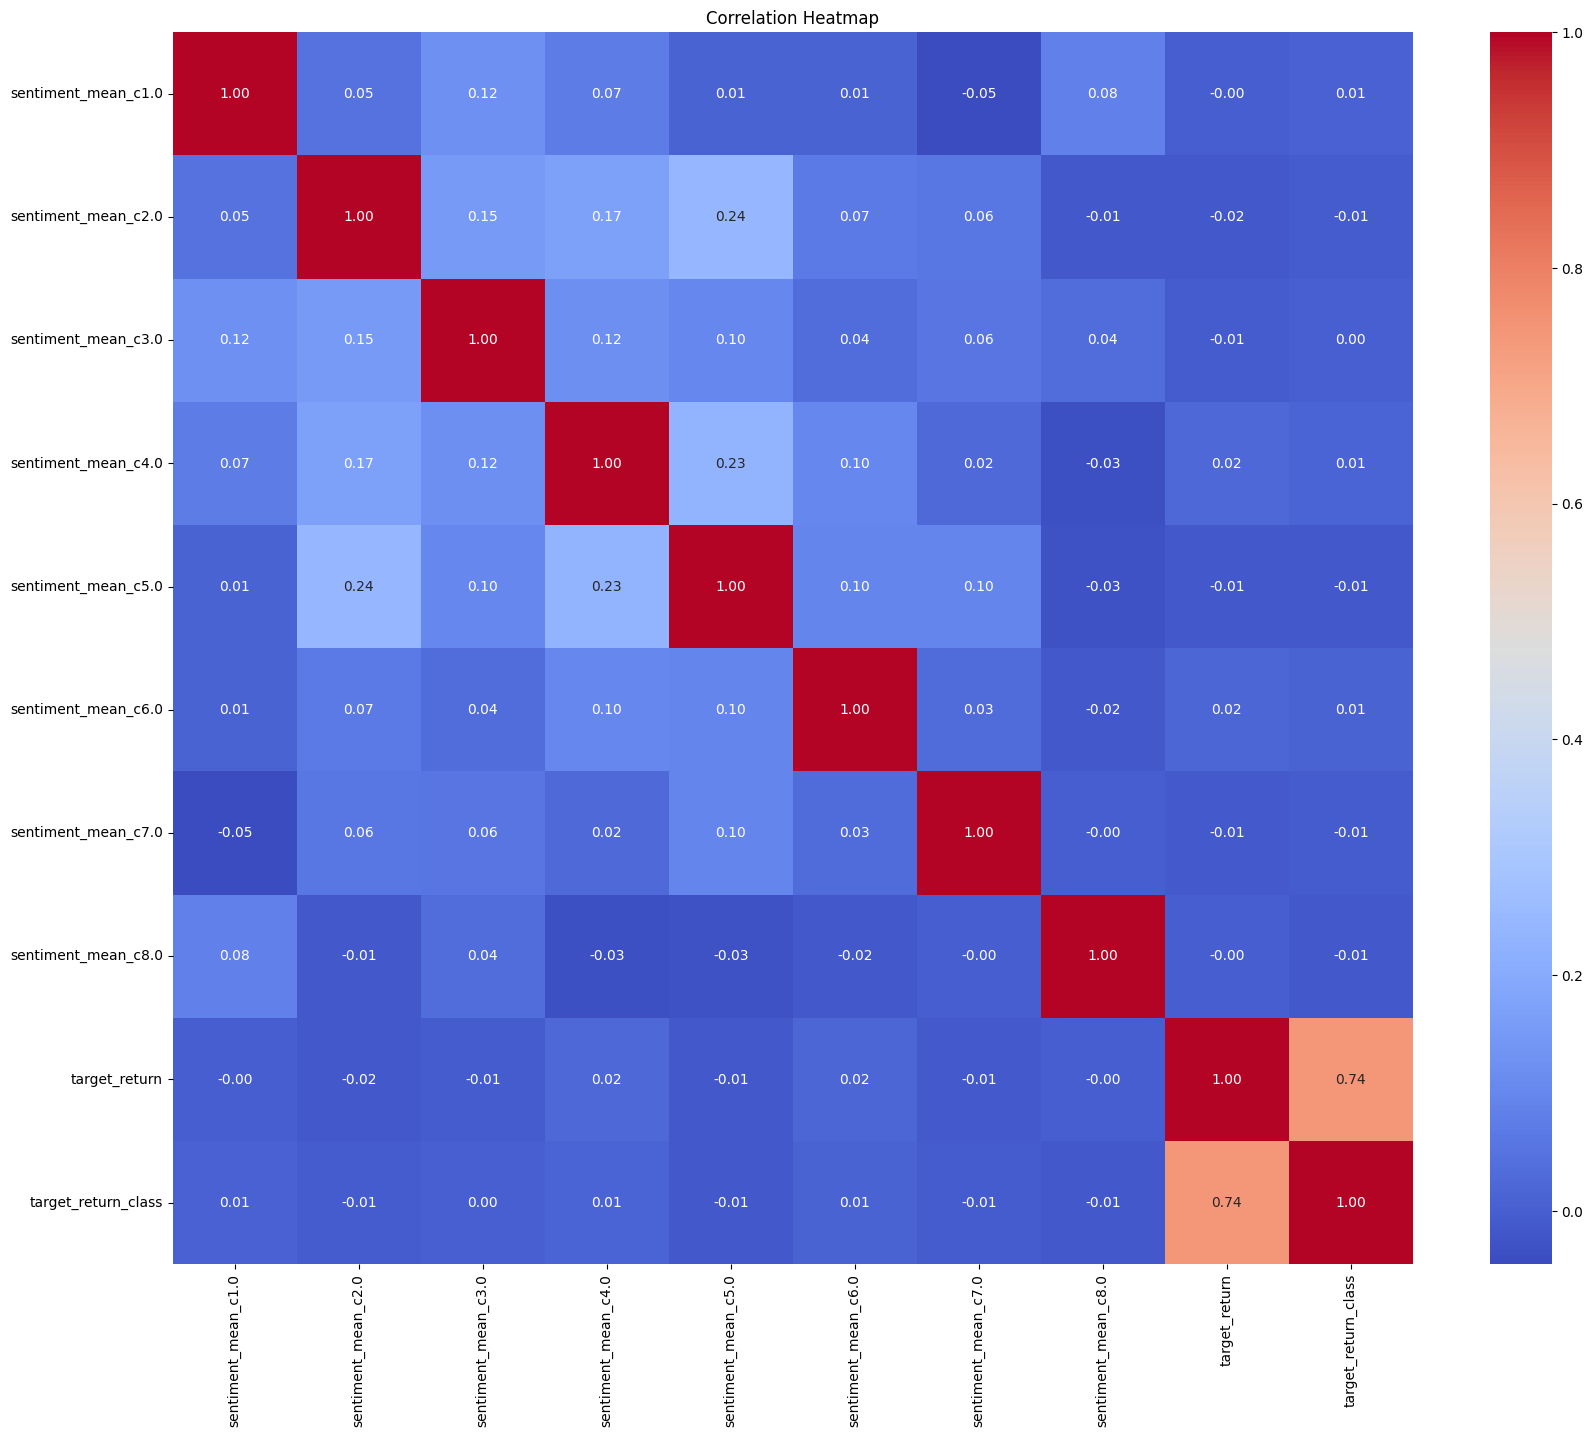

In [142]:
plt.figure(figsize=(20, 16))
sns.heatmap(df[sent_mean_cols + ["target_return", "target_return_class"]].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [143]:
def save_barh(features, values, title, filename, top_n=None):
    features = np.array(features)
    values = np.array(values)

    # optional: nur Top-N nach Betrag
    if top_n is not None:
        idx = np.argsort(np.abs(values))[::-1][:top_n]
        features, values = features[idx], values[idx]

    # sortiere für schönere barh-Anordnung (klein -> groß)
    order = np.argsort(values)
    features, values = features[order], values[order]

    plt.figure(figsize=(10, 6))
    plt.barh(features, values)
    plt.axvline(0, color="black", linestyle="--", linewidth=1)
    plt.title(title)
    plt.xlabel("Importance / Effect")
    plt.tight_layout()
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"Saved: {filename}")

In [144]:
X= df[features]
y_reg= df['target_return']
y_cla= df['target_return_class']

In [145]:
X_train= X.loc[X.index <= cutoff_date]
X_test= X.loc[X.index > cutoff_date]

y_train_reg= y_reg.loc[y_reg.index <= cutoff_date]
y_test_reg= y_reg.loc[y_reg.index > cutoff_date]

y_train_cla= y_cla.loc[y_cla.index <= cutoff_date]
y_test_cla= y_cla.loc[y_cla.index > cutoff_date]

In [146]:
lin_model_reg = LinearRegression().fit(X_train, y_train_reg)

In [147]:
log_model_cla = LogisticRegression(max_iter=2000, multi_class="multinomial")
log_model_cla.fit(X_train, y_train_cla)

c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(max_iter=2000, multi_class='multinomial')

In [148]:
lin_pred_reg = lin_model_reg.predict(X_test)
log_pred_cla = log_model_cla.predict(X_test)
log_pred_clf_probs = log_model_cla.predict_proba(X_test)

log_precision_per_class = precision_score(y_test_cla,log_pred_cla,average=None)

In [149]:
print(f"Linear MAE (Next return prediction): {mean_absolute_error(y_test_reg, lin_pred_reg):.6f}")
print(f"R2 Score: {r2_score(y_test_reg, lin_pred_reg):.6f}")

print(f"Logistic Accuracy (Classification prediction): {accuracy_score(y_test_cla, log_pred_cla):.4f}")
print(f"F1 macro: {f1_score(y_test_cla, log_pred_cla, average='macro'):.4f}")
print(f"ROC AUC OVR: {roc_auc_score(y_test_cla, log_pred_clf_probs, multi_class='ovr'):.4f}")
print(f"Precision Klasse Negative: {log_precision_per_class[0]:.4f}")
print(f"Precision Klasse Possitiv: {log_precision_per_class[2]:.4f}")

Linear MAE (Next return prediction): 0.004699
R2 Score: -0.018111
Logistic Accuracy (Classification prediction): 0.3281
F1 macro: 0.2368
ROC AUC OVR: 0.5212
Precision Klasse Negative: 0.3467
Precision Klasse Possitiv: 0.3268


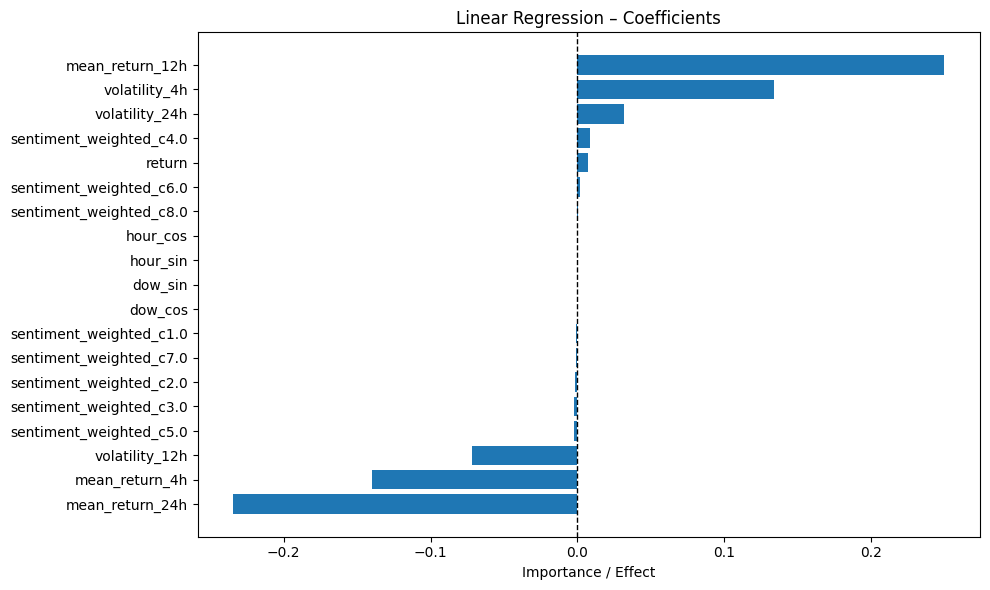

Saved: xai_linreg_coefs.png


In [150]:
lin_imp = lin_model_reg.coef_  # LinearRegression().fit(...)
save_barh(features, lin_imp,
          "Linear Regression – Coefficients",
          "xai_linreg_coefs.png",
          top_n=20)

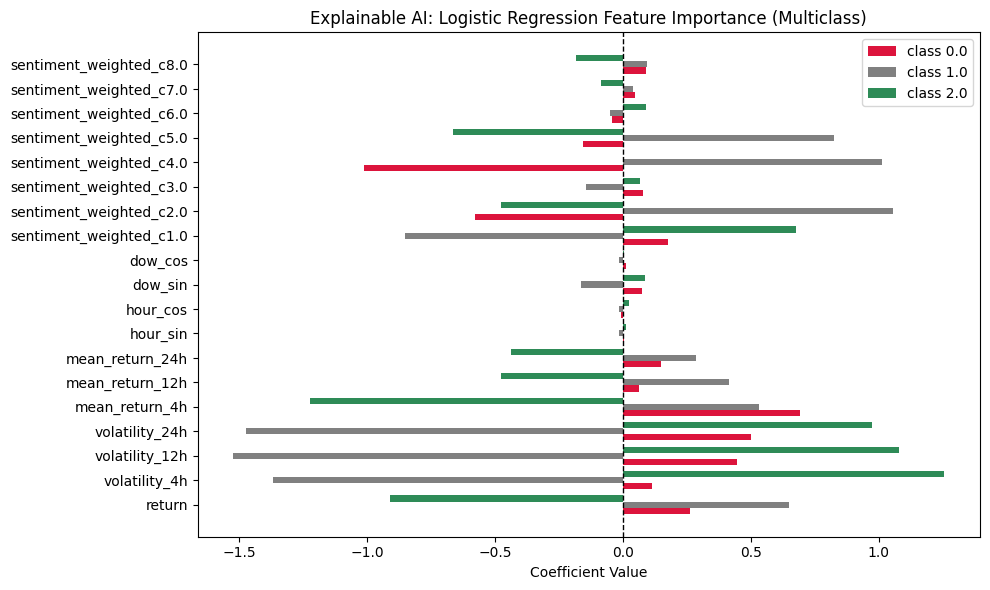

In [151]:
coefs = log_model_cla.coef_      # shape (3, n_features)
classes = log_model_cla.classes_

y_pos = np.arange(len(features))
bar_height = 0.25

plt.figure(figsize=(10,6))

colors = ["crimson", "gray", "seagreen"]  # neg, neutral, pos (z.B.)

for i, cls in enumerate(classes):
    plt.barh(
        y_pos + (i-1)*bar_height,    # verschiebt die Balken
        coefs[i],
        height=bar_height,
        label=f"class {cls}",
        color=colors[i]
    )

plt.yticks(y_pos, features)
plt.xlabel("Coefficient Value")
plt.title("Explainable AI: Logistic Regression Feature Importance (Multiclass)")
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
rfr_model_reg = RandomForestRegressor(
    n_estimators=50,
    max_depth=6,
    n_jobs=-1,
    random_state=42
)
rfr_model_reg.fit(X_train, y_train_reg)

RandomForestRegressor(max_depth=6, n_estimators=50, n_jobs=-1, random_state=42)

In [30]:
rfc_model_cla = RandomForestClassifier(
    n_estimators=50,
    max_depth=6,
    n_jobs=-1,
    random_state=42
)
rfc_model_cla.fit(X_train, y_train_cla)

RandomForestClassifier(max_depth=6, n_estimators=50, n_jobs=-1, random_state=42)

In [31]:
rfr_pred_reg = rfr_model_reg.predict(X_test)
rfc_pred_cla = rfc_model_cla.predict(X_test)
rfc_pred_probs = rfc_model_cla.predict_proba(X_test)

rfc_precision_per_class = precision_score(y_test_cla,rfc_pred_cla,average=None)

In [32]:
print(f"Random Forest Regressor MAE (Next return prediction): {mean_absolute_error(y_test_reg, rfr_pred_reg):.6f}")
print(f"R2 Score: {r2_score(y_test_reg, rfr_pred_reg):.6f}")

print(f"Random Forest Classifier Accuracy (Classification prediction): {accuracy_score(y_test_cla, rfc_pred_cla):.4f}")
print(f"F1 macro: {f1_score(y_test_cla, rfc_pred_cla, average='macro'):.4f}")
print(f"ROC AUC OVR: {roc_auc_score(y_test_cla, rfc_pred_probs, multi_class='ovr'):.4f}")
print(f"Precision Klasse Negative: {rfc_precision_per_class[0]:.4f}")
print(f"Precision Klasse Possitiv: {rfc_precision_per_class[2]:.4f}")

Random Forest Regressor MAE (Next return prediction): 0.002488
R2 Score: -0.031999
Random Forest Classifier Accuracy (Classification prediction): 0.5388
F1 macro: 0.2740
ROC AUC OVR: 0.5795
Precision Klasse Negative: 0.2500
Precision Klasse Possitiv: 0.3801


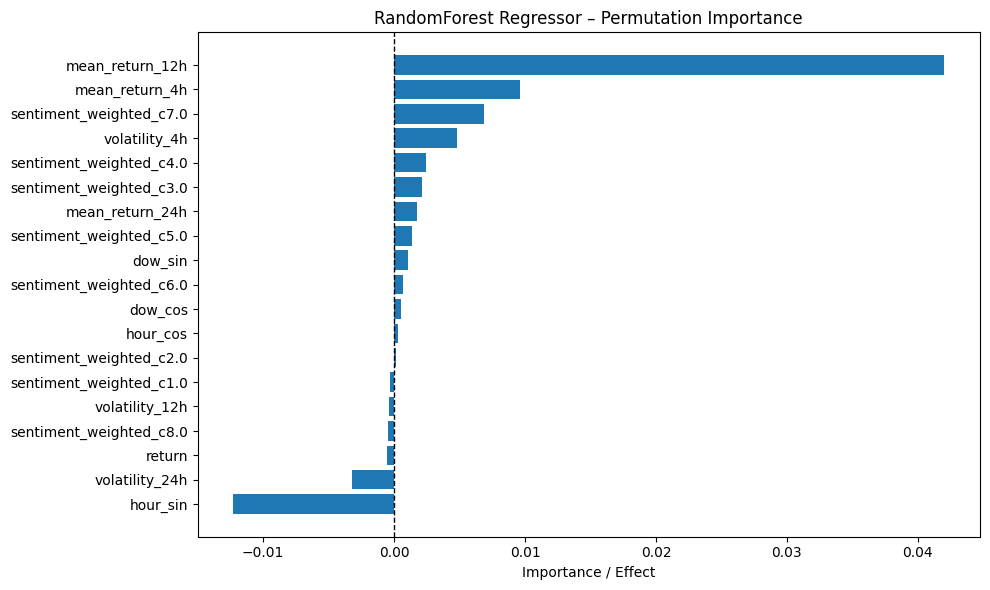

Saved: xai_rfreg_perm_importance.png


In [33]:
perm = permutation_importance(
    rfr_model_reg,         # RandomForestRegressor
    X_test, y_test_reg,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

rf_imp = perm.importances_mean
save_barh(features, rf_imp,
          "RandomForest Regressor – Permutation Importance",
          "xai_rfreg_perm_importance.png",
          top_n=20)

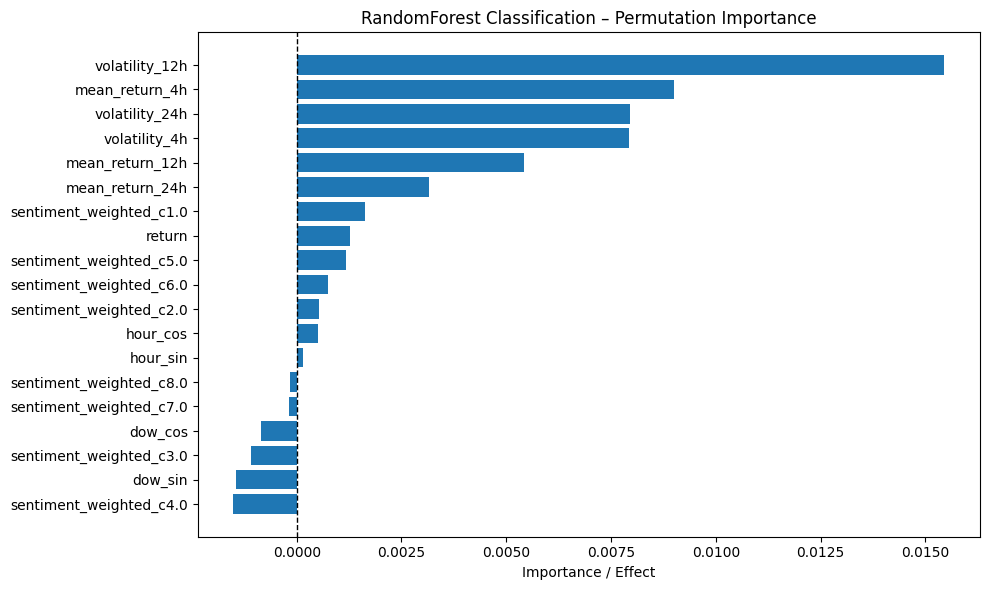

Saved: xai_rfcla_perm_importance.png


In [34]:
perm = permutation_importance(
    rfc_model_cla,
    X_test, y_test_cla,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring="f1_macro"
)

rf_imp = perm.importances_mean  # (n_features,)
save_barh(features, rf_imp,
          "RandomForest Classification – Permutation Importance",
          "xai_rfcla_perm_importance.png",
          top_n=20)

In [35]:
XGB_model_reg = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    objective='reg:squarederror'
)
XGB_model_reg.fit(X_train, y_train_reg)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.05, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=6, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=200, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [36]:
XGB_model_cla = XGBClassifier(
    n_estimators=150,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)
XGB_model_cla.fit(X_train, y_train_cla)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=150,
              n_jobs=-1, num_class=3, num_parallel_tree=None, ...)

In [37]:
XGB_pred_reg = XGB_model_reg.predict(X_test)
XGB_pred_cla = XGB_model_cla.predict(X_test)
XGB_pred_probs = XGB_model_cla.predict_proba(X_test)

XGB_precision_per_class = precision_score(y_test_cla,XGB_pred_cla,average=None)

In [38]:
print(f"XG Boost Regressor MAE (Next return prediction): {mean_absolute_error(y_test_reg, XGB_pred_reg):.6f}")
print(f"R2 Score: {r2_score(y_test_reg, XGB_pred_reg):.6f}")

print(f"XG Boost Classifier Accuracy (Classification prediction): {accuracy_score(y_test_cla, XGB_pred_cla):.4f}")
print(f"F1 macro: {f1_score(y_test_cla, XGB_pred_cla, average='macro'):.4f}")
print(f"ROC AUC OVR: {roc_auc_score(y_test_cla, XGB_pred_probs, multi_class='ovr'):.4f}")
print(f"Precision Klasse Negative: {XGB_precision_per_class[0]:.4f}")
print(f"Precision Klasse Possitiv: {XGB_precision_per_class[2]:.4f}")

XG Boost Regressor MAE (Next return prediction): 0.002524
R2 Score: -0.071962
XG Boost Classifier Accuracy (Classification prediction): 0.5304
F1 macro: 0.3124
ROC AUC OVR: 0.5696
Precision Klasse Negative: 0.2500
Precision Klasse Possitiv: 0.3514


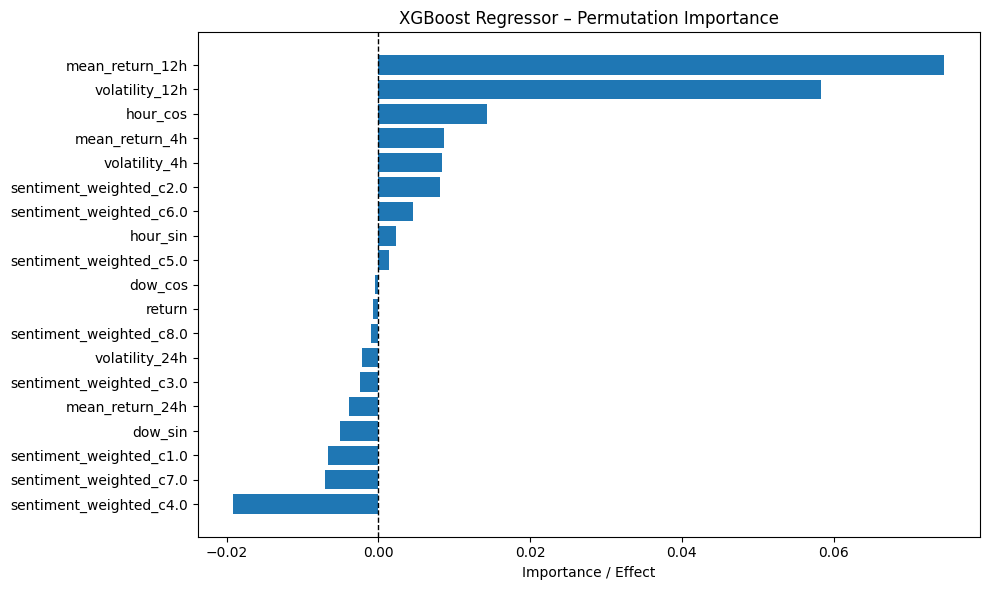

Saved: xai_xgbreg_perm_importance.png


In [39]:
perm = permutation_importance(
    XGB_model_reg,        # XGBRegressor
    X_test, y_test_reg,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

xgb_imp = perm.importances_mean
save_barh(features, xgb_imp,
          "XGBoost Regressor – Permutation Importance",
          "xai_xgbreg_perm_importance.png",
          top_n=20)

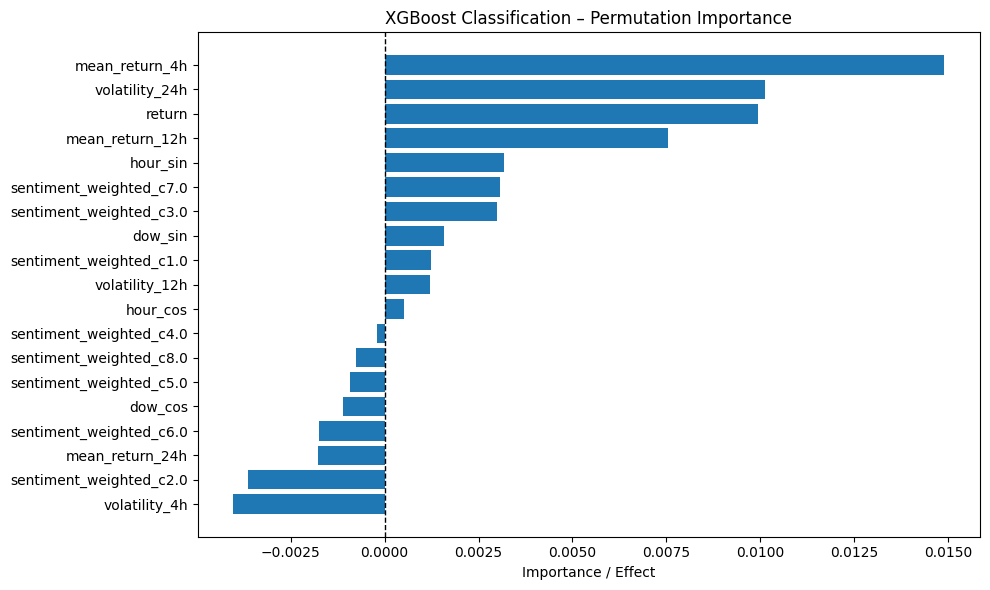

Saved: xai_xgbcla_perm_importance.png


In [40]:
perm = permutation_importance(
    XGB_model_cla,
    X_test, y_test_cla,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring="f1_macro"
)

xgb_imp = perm.importances_mean
save_barh(features, xgb_imp,
          "XGBoost Classification – Permutation Importance",
          "xai_xgbcla_perm_importance.png",
          top_n=20)

In [41]:
X_val = df[features].values
y_reg_val = df['target_return'].values
y_cla_val = df['target_return_class'].values

In [42]:
def create_sequences(X, y_r, y_c, window=20):
    Xs, yr, yc = [], [], []
    for i in range(window, len(X)):
        Xs.append(X[i-window:i])
        yr.append(y_r[i])
        yc.append(y_c[i])
    return np.array(Xs), np.array(yr), np.array(yc)

In [43]:
WINDOW= 96

In [44]:
X_seq, y_reg_seq, y_clf_seq = create_sequences(X_val, y_reg_val, y_cla_val, WINDOW)

In [45]:
seq_index = df.index[WINDOW:]

In [46]:
train_mask = seq_index <= cutoff_date
test_mask  = seq_index > cutoff_date

In [47]:
X_train_seq = X_seq[train_mask]
X_test_seq  = X_seq[test_mask]

y_train_reg_seq = y_reg_seq[train_mask]
y_test_reg_seq  = y_reg_seq[test_mask]

y_train_cla_seq = y_clf_seq[train_mask]
y_test_cla_seq  = y_clf_seq[test_mask]

In [48]:
scaler = MinMaxScaler()
n_feat = X_train_seq.shape[-1]

X_train_seq_2d = X_train_seq.reshape(-1, n_feat)
X_test_seq_2d  = X_test_seq.reshape(-1, n_feat)

X_train_seq_scaled = scaler.fit_transform(X_train_seq_2d).reshape(X_train_seq.shape)
X_test_seq_scaled  = scaler.transform(X_test_seq_2d).reshape(X_test_seq.shape)

In [49]:
baseline_vec = np.median(
    X_train_seq_scaled.reshape(-1, n_feat),
    axis=0
)

In [50]:
def ablation_importance_seq_reg(model, X_seq, baseline_vec, n_samples=300):
    n = min(n_samples, len(X_seq))
    idx = np.random.choice(len(X_seq), size=n, replace=False)
    Xb = X_seq[idx].copy()

    base = model.predict(Xb, verbose=0).reshape(-1)

    imps = np.zeros(Xb.shape[2], dtype=float)
    for j in range(Xb.shape[2]):
        X_abl = Xb.copy()
        X_abl[:, :, j] = baseline_vec[j]   # ✅ hier
        changed = model.predict(X_abl, verbose=0).reshape(-1)
        imps[j] = np.mean(np.abs(base - changed))
    return imps


In [51]:
def ablation_importance_seq_cla(model, X_seq, class_index=2, baseline_vec=None, n_samples=300):
    # X_seq: (N, WINDOW, n_features)

    n = min(n_samples, len(X_seq))
    idx = np.random.choice(len(X_seq), size=n, replace=False)
    Xb = X_seq[idx].copy()

    base = model.predict(Xb, verbose=0)[:, class_index]  # (n,)

    imps = np.zeros(Xb.shape[2], dtype=float)

    for j in range(Xb.shape[2]):
        X_abl = Xb.copy()

        if baseline_vec is None:
            X_abl[:, :, j] = 0.0
        else:
            X_abl[:, :, j] = baseline_vec[j]

        changed = model.predict(X_abl, verbose=0)[:, class_index]
        imps[j] = np.mean(np.abs(base - changed))

    return imps


In [52]:
gru_model_reg = Sequential([
    Input(shape=(WINDOW, len(features))),
    GRU(32),
    Dropout(0.2),
    Dense(1)
])
gru_model_reg.compile(optimizer=Adam(0.001), loss='mae')
gru_model_reg.fit(X_train_seq_scaled, y_train_reg_seq, epochs=3, batch_size=256, verbose=0)

In [53]:
gru_model_cla = Sequential([
    Input(shape=(WINDOW, len(features))),
    GRU(32),
    Dropout(0.2),
    Dense(3, activation='softmax')
])
gru_model_cla.compile(optimizer=Adam(0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
gru_model_cla.fit(X_train_seq_scaled, y_train_cla_seq, epochs=3, batch_size=256, verbose=0)

In [54]:
gru_pred_reg = gru_model_reg.predict(X_test_seq_scaled, batch_size=512, verbose=0)
gru_pred_proba = gru_model_cla.predict(X_test_seq_scaled)
gru_pred_cla = gru_pred_proba.argmax(axis=1)

gru_precision_per_class = precision_score(y_test_cla_seq,gru_pred_cla,average=None)

178/178 [==============================] - 4s 16ms/step


In [55]:
print(f"Gru Regressor MAE (Next return prediction): {mean_absolute_error(y_test_reg_seq, gru_pred_reg):.6f}")
print(f"R2 Score: {r2_score(y_test_reg_seq, gru_pred_reg):.6f}")

print(f"Gru Boost Classifier Accuracy (Classification prediction): {accuracy_score(y_test_cla_seq, gru_pred_cla):.4f}")
print(f"F1 macro: {f1_score(y_test_cla_seq, gru_pred_cla, average='macro'):.4f}")
print(f"ROC AUC OVR: {roc_auc_score(y_test_cla_seq, gru_pred_proba, multi_class='ovr'):.4f}")
print(f"Precision Klasse Negative: {gru_precision_per_class[0]:.4f}")
print(f"Precision Klasse Possitiv: {gru_precision_per_class[2]:.4f}")

Gru Regressor MAE (Next return prediction): 0.004596
R2 Score: -1.760937
Gru Boost Classifier Accuracy (Classification prediction): 0.5328
F1 macro: 0.2470
ROC AUC OVR: 0.5660
Precision Klasse Negative: 0.2475
Precision Klasse Possitiv: 0.2800


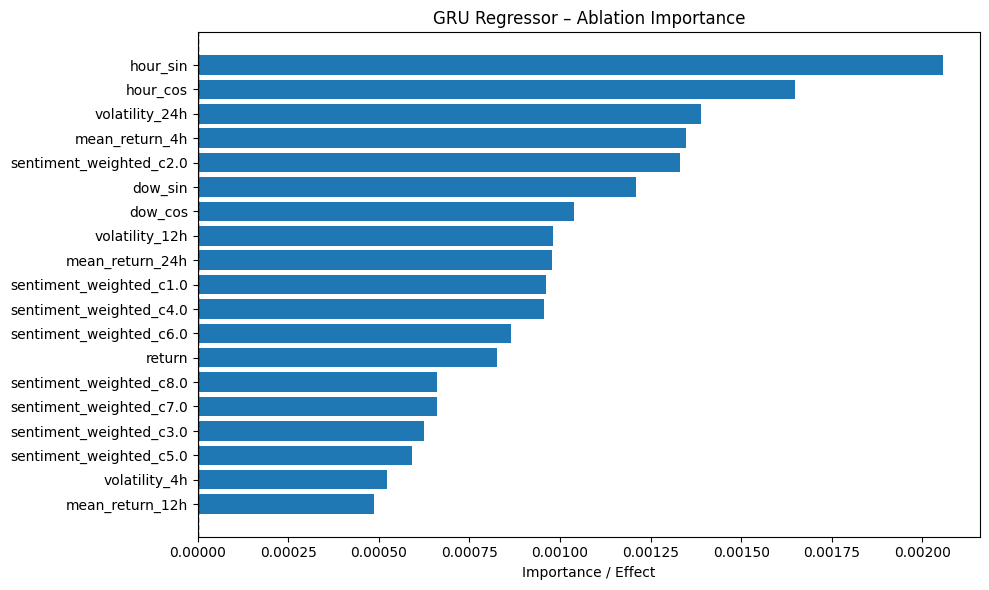

Saved: xai_gru_reg_ablation_importance.png


In [56]:
gru_reg_imp = ablation_importance_seq_reg(gru_model_reg, X_test_seq_scaled, baseline_vec)
save_barh(features, gru_reg_imp,
          "GRU Regressor – Ablation Importance",
          "xai_gru_reg_ablation_importance.png",
          top_n=20)

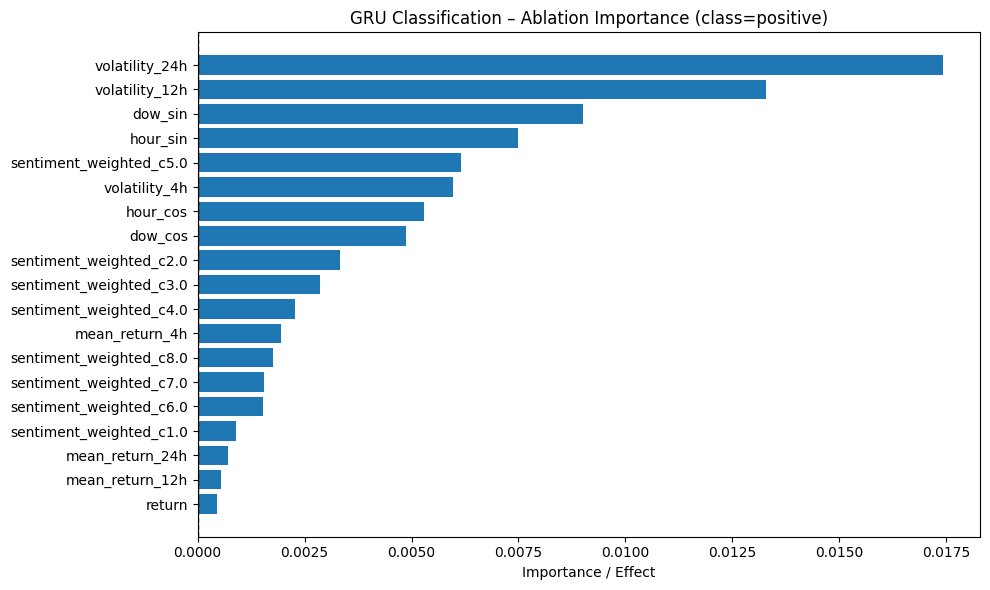

Saved: xai_gru_cla_ablation_importance.png


In [57]:
gru_imp = ablation_importance_seq_cla(gru_model_cla, X_test_seq_scaled, class_index=2, baseline_vec=baseline_vec)
save_barh(features, gru_imp,
          "GRU Classification – Ablation Importance (class=positive)",
          "xai_gru_cla_ablation_importance.png",
          top_n=20)

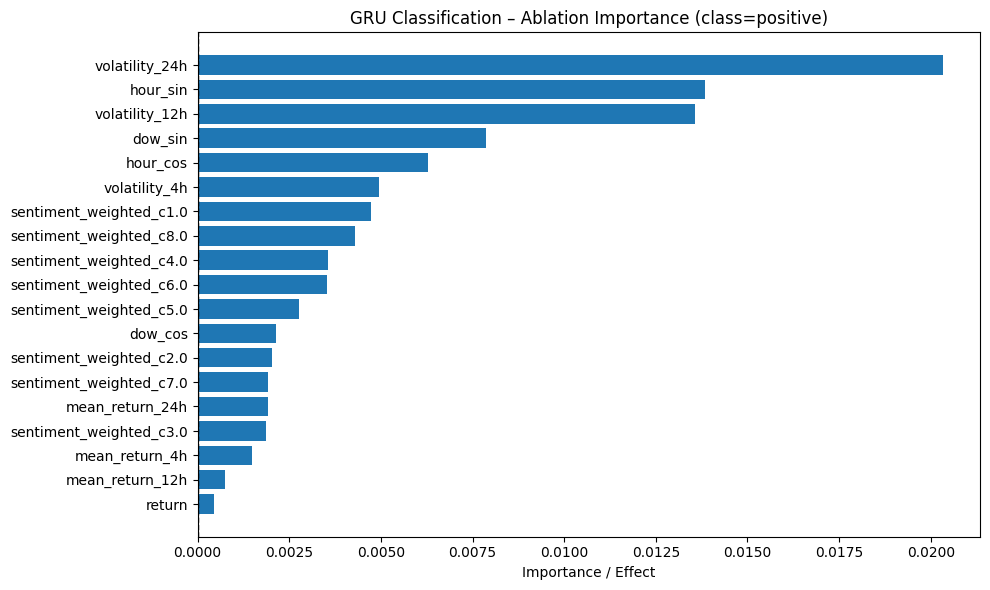

Saved: xai_gru_cla_ablation_importance.png


In [58]:
gru_imp = ablation_importance_seq_cla(gru_model_cla, X_test_seq_scaled, class_index=0, baseline_vec=baseline_vec)
save_barh(features, gru_imp,
          "GRU Classification – Ablation Importance (class=positive)",
          "xai_gru_cla_ablation_importance.png",
          top_n=20)

In [59]:
def build_lstm(output_type='reg'):
    if output_type == 'reg':
        output_units = 1
        activation = 'linear'
        loss = 'mae'
        metrics = []

    elif output_type == 'cla':
        output_units = 3          # <- 3 Klassen!
        activation = 'softmax'   # <- statt sigmoid
        loss = 'sparse_categorical_crossentropy'
        metrics = ['accuracy']

    model = Sequential([
        Input(shape=(WINDOW, len(features))),
        LSTM(64, return_sequences=True),
        Dropout(0.2),
        LSTM(32),
        Dropout(0.2),
        Dense(output_units, activation=activation)
    ])

    opt = Adam(learning_rate=0.001)
    model.compile(optimizer=opt, loss=loss, metrics=metrics)
    return model

In [60]:
lstm_model_reg = build_lstm('reg')
lstm_model_reg.fit(X_train_seq_scaled, y_train_reg_seq, epochs=5, batch_size=128, verbose=0)

In [61]:
lstm_model_cla = build_lstm('cla')
lstm_model_cla.fit(X_train_seq_scaled, y_train_cla_seq, epochs=5, batch_size=128, verbose=0)

In [62]:
lstm_pred_reg = lstm_model_reg.predict(X_test_seq_scaled)
lstm_pred_cla_probs = lstm_model_cla.predict(X_test_seq_scaled)
lstm_pred_cla= lstm_pred_cla_probs.argmax(axis=1)

lstm_precision_per_class = precision_score(y_test_cla_seq,gru_pred_cla,average=None)

178/178 [==============================] - 9s 41ms/step


In [63]:
print(f"LSTM Regressor MAE (Next return prediction): {mean_absolute_error(y_test_reg_seq, lstm_pred_reg):.6f}")
print(f"R2 Score: {r2_score(y_test_reg_seq, lstm_pred_reg):.6f}")

print(f"LSTM Boost Classifier Accuracy (Classification prediction): {accuracy_score(y_test_cla_seq, lstm_pred_cla):.4f}")
print(f"F1 macro: {f1_score(y_test_cla_seq, lstm_pred_cla, average='macro'):.4f}")
print(f"ROC AUC OVR: {roc_auc_score(y_test_cla_seq, lstm_pred_cla_probs, multi_class='ovr'):.4f}")
print(f"Precision Klasse Negative: {lstm_precision_per_class[0]:.4f}")
print(f"Precision Klasse Possitiv: {lstm_precision_per_class[2]:.4f}")

LSTM Regressor MAE (Next return prediction): 0.002514
R2 Score: -0.025197
LSTM Boost Classifier Accuracy (Classification prediction): 0.5328
F1 macro: 0.2666
ROC AUC OVR: 0.5651
Precision Klasse Negative: 0.2475
Precision Klasse Possitiv: 0.2800


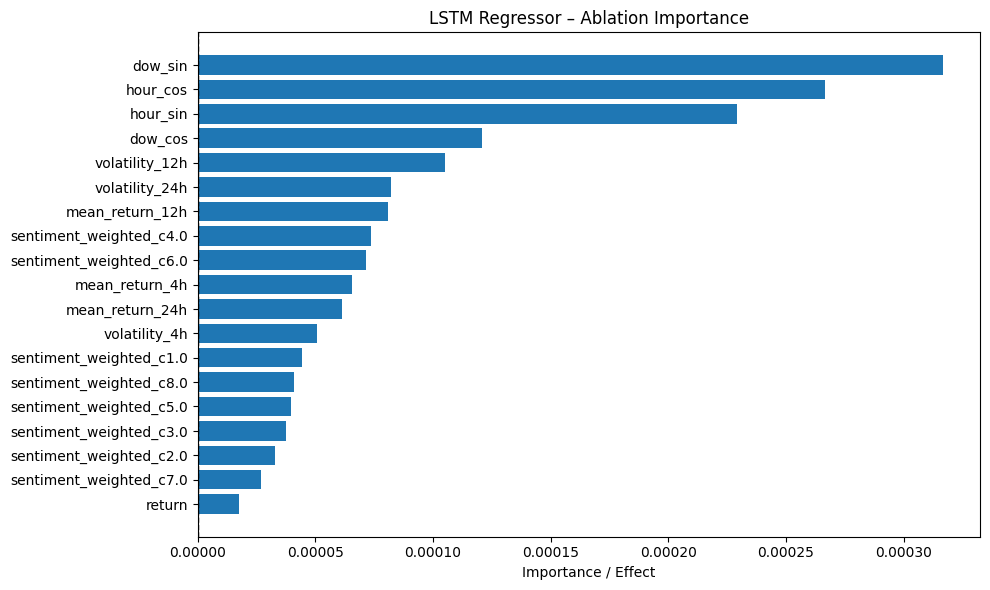

Saved: xai_lstm_reg_ablation_importance.png


In [64]:
lstm_reg_imp = ablation_importance_seq_reg(lstm_model_reg, X_test_seq_scaled, baseline_vec)
save_barh(features, lstm_reg_imp,
          "LSTM Regressor – Ablation Importance",
          "xai_lstm_reg_ablation_importance.png",
          top_n=20)

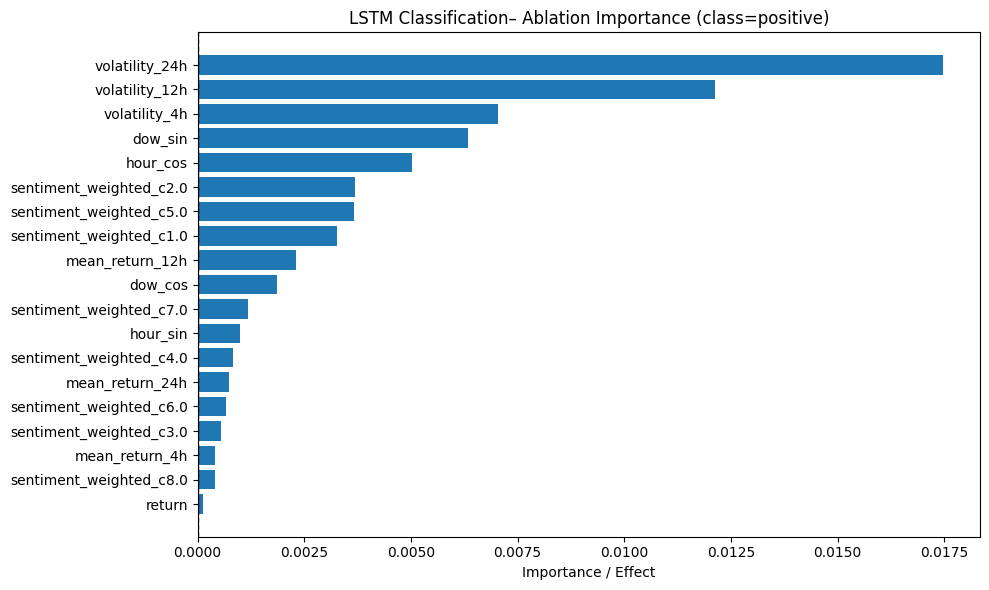

Saved: xai_lstm_cla_ablation_importance.png


In [65]:
lstm_imp = ablation_importance_seq_cla(lstm_model_cla, X_test_seq_scaled, class_index=2, baseline_vec=baseline_vec)
save_barh(features, lstm_imp,
          "LSTM Classification– Ablation Importance (class=positive)",
          "xai_lstm_cla_ablation_importance.png",
          top_n=20)

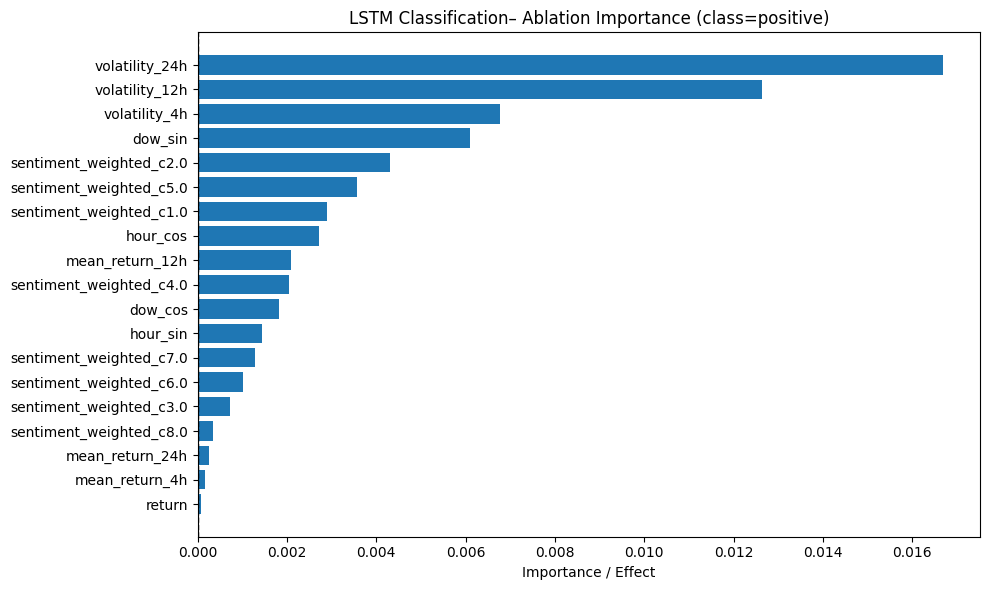

Saved: xai_lstm_cla_ablation_importance.png


In [66]:
lstm_imp = ablation_importance_seq_cla(lstm_model_cla, X_test_seq_scaled, class_index=0, baseline_vec=baseline_vec)
save_barh(features, lstm_imp,
          "LSTM Classification– Ablation Importance (class=positive)",
          "xai_lstm_cla_ablation_importance.png",
          top_n=20)